![HeatSafe](figuras/banner.png)

# HeatSafe · Previsão de dia de calor perigoso

**Global Solution 2026.2 · CitizenTech · Inteligência Artificial & Machine Learning**
FIAP · Engenharia de Software · 3º ano (Fev)

| Integrante | RM |
|---|---|
| Felipe Braunstein e Silva | RM554483 |
| Felipe do Nascimento Fernandes | RM554598 |
| Henrique Ignacio Bartalo | RM555274 |
| Gustavo Henrique Martins | RM556956 |

> **O HeatSafe** é um dispositivo dentro da casa de idosos que passam o dia sozinhos. Ele mede o calor da casa e percebe se a pessoa está se movimentando, e avisa a família ou a UBS quando a combinação fica perigosa.
>
> **Este notebook** constrói a peça que olha para o dia seguinte: na véspera, às 19h, o modelo diz se **amanhã** será um dia de calor perigoso em São Paulo. Se for, o HeatSafe liga o **modo vigilância** (lembretes de água mais frequentes, família e agente de saúde avisados com antecedência).

### Resumo em 30 segundos

| | |
|---|---|
| **Pergunta** | Às 19h de hoje, dá para saber se amanhã o índice de calor máximo em SP vai chegar a 30 °C ou mais? |
| **Dados** | INMET, estação A701 (Mirante de Santana), **96.430 horas reais** de 2015 a 2025 |
| **Modelo** | **Random Forest**, escolhido contra o XGBoost por validação cruzada temporal (66 combinações de hiperparâmetros testadas no total) |
| **Resultado no teste (2023–2025)** | Avisou na véspera **9 de cada 10 dias perigosos** (216 de 239) e **98% dos dias mais extremos** (≥ 32 °C) |
| **Onda de calor de nov/2023** | **10 de 11** dias perigosos avisados na véspera |
| **Honestidade** | Uma regra simples ("se hoje passou de 28,6 °C, amanhã também passa") já acerta muito. O modelo a supera em ordenação (AP 0,774 contra 0,713) e entrega uma **probabilidade calibrada**, que permite um alerta em dois níveis |

**Roteiro:** 1. Problema → 2. Dados reais → 3. Preparação → 4. Escolha do modelo → 5. Treino com diferentes hiperparâmetros → 6. Resultados em treino e teste → 7. Conclusão para o cidadão → 8. Exportação para o serviço de previsão

In [1]:
# Bibliotecas e identidade visual do HeatSafe
import inspect, json, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import sklearn, xgboost
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, fbeta_score, precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

import atributos as at  # engenharia de atributos do HeatSafe (arquivo atributos.py, ao lado deste notebook)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
SEMENTE = 42
DADOS, FIG, MODELO = Path("dados"), Path("figuras"), Path("modelo")
FIG.mkdir(exist_ok=True); MODELO.mkdir(exist_ok=True)

# Paleta HeatSafe (validada para daltonismo: laranja x azul x verde, ΔE >= 10)
LARANJA, AZUL, VERDE = "#E8590C", "#2F6DB5", "#2E9E6B"
CINZA, CINZA_CLARO, TINTA, TINTA2 = "#8A94A6", "#D5DAE1", "#1F2A44", "#5B6475"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10.5, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlecolor": TINTA, "axes.labelcolor": TINTA2, "axes.edgecolor": CINZA_CLARO, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#EEF0F3", "grid.linewidth": 0.8,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "legend.frameon": False, "axes.titlelocation": "left",
})
FONTE = "HeatSafe · Dados: INMET/BDMEP, estação A701 (São Paulo – Mirante)"

def finalizar(fig, nome, fonte=FONTE):
    fig.text(0.005, -0.01, fonte, fontsize=8, color=TINTA2, ha="left", va="top")
    fig.savefig(FIG / nome, bbox_inches="tight", facecolor="white")
    plt.show()

print(f"Python {platform.python_version()} · pandas {pd.__version__} · scikit-learn {sklearn.__version__} · xgboost {xgboost.__version__}")

Python 3.12.2 · pandas 3.0.3 · scikit-learn 1.8.0 · xgboost 3.2.0


## 1. O problema e a pergunta de Machine Learning

**Cidadão:** idosos que passam o dia sozinhos em casas quentes, como a Dona Maria (78 anos, casa térrea com telha de fibrocimento na zona leste). Nas entrevistas com as personas do projeto, ela contou que *"não sente sede"*, evita beber água por causa do diurético e já desmaiou sozinha no verão. A filha, Ana, disse que *"se o celular apitar toda hora, vou acabar ignorando"*. A agente de saúde, Rosa, disse que *"no dia de calor não sei quem está pior naquele momento"*.

**Por que prever na véspera?** O dispositivo do HeatSafe reage ao calor que já está dentro da casa. Saber **um dia antes** permite se preparar: a família programa ligações, a UBS monta a rota de visitas, o dispositivo antecipa os lembretes de água. A Defesa Civil avisa a cidade inteira do mesmo jeito; o HeatSafe usa a previsão para ativar o cuidado **casa a casa**.

### A pergunta

> **Às 19h de hoje, com o que a estação meteorológica já mediu, dá para saber se amanhã o índice de calor máximo em São Paulo vai chegar a 30 °C ou mais?**

- **Tipo:** classificação binária (1 = amanhã é dia perigoso, 0 = não é).
- **Índice de calor:** a "sensação térmica" oficial da NOAA (EUA), que combina temperatura e umidade. É a mesma fórmula do dispositivo ESP32 do HeatSafe.
- **Por que 30 °C e não 32 °C?** Na tabela do HeatSafe, 32 °C é o início do nível *Cautela extrema* **dentro da casa**. A estação do INMET fica num morro ventilado a 792 m de altitude e mede **menos** calor do que uma casa com telha de fibrocimento. Usamos 30 °C na estação como gatilho, com margem de segurança. Na seção 4 mostramos, com dados, que com 32 °C há tão poucos exemplos que nenhum modelo supera uma regra simples.

### Qual erro é pior?

| Erro | O que acontece | Custo |
|---|---|---|
| **Falso negativo** (era perigoso e o modelo não avisou) | Dona Maria passa o dia quente sem o modo vigilância | **Alto:** risco à saúde |
| **Falso positivo** (avisou e o dia não foi perigoso) | O modo vigilância liga sem necessidade | **Baixo:** o alerta à família só dispara se o sensor **dentro da casa** confirmar o calor e a inatividade |

Por isso priorizamos o **recall** (proporção de dias perigosos que o modelo pega), usando o **F2**, uma média entre recall e precisão que dá **peso 2 ao recall**. A precisão continua importante: alarmes falsos demais fazem a família ignorar o sistema, como a Ana avisou.

## 2. Dados reais e públicos

| Item | Valor |
|---|---|
| Fonte | **INMET** (Instituto Nacional de Meteorologia), BDMEP: dados históricos anuais das estações automáticas |
| Link | https://portal.inmet.gov.br/dadoshistoricos |
| Estação | **A701 – São Paulo (Mirante de Santana)**, lat −23,48 · lon −46,62 · 792 m |
| Período | **01/01/2015 a 31/12/2025**, medições **horárias** (96.430 horas, 4.018 dias) |
| Download | 08/11/2026, arquivos `<ANO>.zip` do portal, só o CSV da A701 de cada ano |
| Tratamento | `dados/preparar_dados.py` (leitura, `-9999` → vazio, UTC → horário de Brasília, índice de calor). Detalhes em `dados/README.md` |

Nenhum dado é simulado. Os dados do dispositivo dentro da casa (que são simulados no protótipo) **não** entram neste modelo.

In [2]:
horario = pd.read_csv(DADOS / "inmet_a701_horario_2015_2025.csv", parse_dates=["data_hora_local"])
diario = pd.read_csv(DADOS / "inmet_a701_diario_2015_2025.csv", parse_dates=["data"], index_col="data")

print(f"Horário: {len(horario):,} linhas de {horario.data_hora_local.min():%d/%m/%Y} a {horario.data_hora_local.max():%d/%m/%Y}")
print(f"Diário : {len(diario):,} dias · {diario.indice_calor_max_c.isna().sum()} dias sem dado suficiente (< 18 h válidas)")
print(f"Horas sem temperatura: {horario.temperatura_c.isna().mean():.1%} · sem umidade: {horario.umidade_pct.isna().mean():.1%}")
horario[["data_hora_local", "temperatura_c", "umidade_pct", "ponto_orvalho_c", "pressao_mb", "radiacao_kj_m2",
         "vento_velocidade_ms", "indice_calor_c", "nivel_risco"]].iloc[12:17]

Horário: 96,430 linhas de 01/01/2015 a 31/12/2025
Diário : 4,018 dias · 22 dias sem dado suficiente (< 18 h válidas)
Horas sem temperatura: 0.4% · sem umidade: 0.4%


,data_hora_local,temperatura_c,umidade_pct,ponto_orvalho_c,pressao_mb,radiacao_kj_m2,vento_velocidade_ms,indice_calor_c,nivel_risco
12,2015-01-01 12:00:00,30.3,42.0,16.0,925.0,3485.9,4.5,30.30,ATENCAO
13,2015-01-01 13:00:00,31.0,38.0,14.8,924.6,3576.8,4.1,30.63,ATENCAO
14,2015-01-01 14:00:00,31.4,36.0,14.7,923.7,3682.7,4.4,30.86,ATENCAO
15,2015-01-01 15:00:00,32.0,37.0,15.5,923.5,3008.7,3.9,31.77,ATENCAO
16,2015-01-01 16:00:00,30.5,39.0,14.9,923.0,2752.2,4.3,30.16,ATENCAO


In [3]:
ic = diario["indice_calor_max_c"]
print(ic.describe().round(2).to_string())
print(f"\nDia mais quente do período: {ic.idxmax():%d/%m/%Y}, índice de calor máximo de {ic.max():.1f} °C")
print(f"Dias com índice de calor >= 30 °C: {(ic >= 30).sum()} de {ic.notna().sum()} ({(ic >= 30).mean():.1%})")
print(f"Dias com índice de calor >= 32 °C: {(ic >= 32).sum()} de {ic.notna().sum()} ({(ic >= 32).mean():.1%})")

count    3996.00
mean       25.66
std         4.36
min        10.56
25%        22.75
50%        26.20
75%        29.02
max        35.47

Dia mais quente do período: 15/11/2023, índice de calor máximo de 35.5 °C
Dias com índice de calor >= 30 °C: 669 de 3996 (16.7%)
Dias com índice de calor >= 32 °C: 169 de 3996 (4.2%)


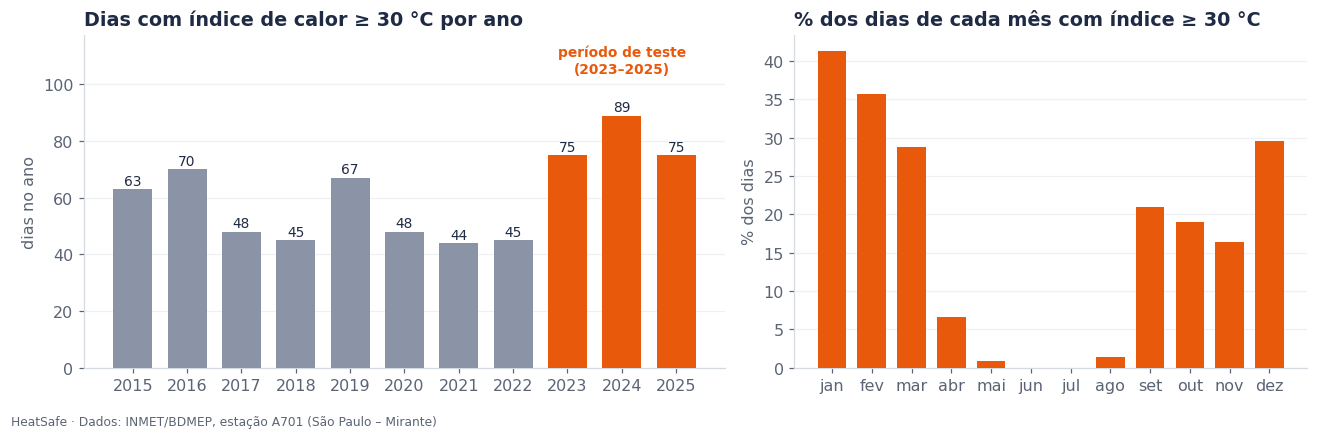

2015–2022: média de 54 dias perigosos/ano · 2023–2025: média de 80 dias/ano


In [4]:
# Figura 1: os dias perigosos estão aumentando, e se concentram de setembro a março
anos = ic.groupby(ic.index.year).apply(lambda s: (s >= 30).sum())
meses = ic.groupby(ic.index.month).apply(lambda s: (s >= 30).mean() * 100)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
cores = [LARANJA if a >= 2023 else CINZA for a in anos.index]
a1.bar(anos.index, anos.values, color=cores, width=0.72, zorder=3)
for x, v in zip(anos.index, anos.values):
    a1.text(x, v + 1.5, str(v), ha="center", fontsize=9, color=TINTA)
a1.set_title("Dias com índice de calor ≥ 30 °C por ano")
a1.set_xticks(anos.index); a1.set_ylabel("dias no ano"); a1.grid(axis="x", visible=False)
a1.set_ylim(0, anos.max() * 1.32)
a1.text(2024, anos.max() * 1.17, "período de teste\n(2023–2025)", color=LARANJA, ha="center", fontsize=9, fontweight="bold")

nomes = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
a2.bar(nomes, meses.values, color=LARANJA, width=0.72, zorder=3)
a2.set_title("% dos dias de cada mês com índice ≥ 30 °C"); a2.set_ylabel("% dos dias"); a2.grid(axis="x", visible=False)
fig.tight_layout()
finalizar(fig, "fig01_dias_perigosos_por_ano_e_mes.png")

print(f"2015–2022: média de {anos.loc[2015:2022].mean():.0f} dias perigosos/ano · 2023–2025: média de {anos.loc[2023:2025].mean():.0f} dias/ano")

**Leitura:** os dias de calor perigoso se concentram de **setembro a março** e ficaram **mais frequentes** a partir de 2023. Esse aumento é ao mesmo tempo um alerta climático (ODS 13) e um desafio para o modelo: ele vai ser testado num período mais quente do que aquele em que aprendeu.

## 3. Preparação dos dados

### 3.1 Só o que se sabe às 19h

O modo vigilância é decidido **às 19h da véspera**. Para o treino ser honesto, cada linha da tabela descreve o dia D usando **apenas as medições de 00h às 18h**, que é o que realmente existe às 19h. Usar o dia D inteiro (até 23h59) seria "espiar o futuro" e daria um resultado melhor no papel do que na vida real.

A engenharia de atributos fica no arquivo `atributos.py`, que também é usado pelo serviço de previsão (disciplina de SOA). Assim, o modelo recebe **exatamente as mesmas colunas** no treino e em produção.

| Grupo | Atributos | Por quê |
|---|---|---|
| Dia D (00h–18h) | índice de calor máximo, temperatura máx/mín/média e às 18h, umidade média e mínima, ponto de orvalho, pressão média e às 18h, radiação solar, chuva, vento | O calor de hoje é o melhor ponto de partida para o de amanhã |
| Memória (D-1, D-2) | índice de calor, temperatura máxima, umidade, ponto de orvalho e pressão dos 2 dias anteriores | Ondas de calor duram vários dias; a pressão caindo pode indicar frente fria |
| Tendência | médias de 3 e 7 dias do índice de calor; variação do índice e da pressão de ontem para hoje | Diferencia "esquentando" de "esfriando" |
| Calendário | mês, seno e cosseno do dia do ano | O calor perigoso tem estação (set–mar) |

**Alvo:** 1 se o índice de calor máximo do **dia D+1** (dia inteiro) for ≥ 30 °C.

In [5]:
print(inspect.getsource(at.resumo_diario_ate_18h))
print(inspect.getsource(at.montar_atributos))

def resumo_diario_ate_18h(horario: pd.DataFrame) -> pd.DataFrame:
    """Resume cada dia usando só as horas de 00h a HORA_CORTE (horário local).

    `horario` precisa ter as colunas do CSV horário do INMET já limpo
    (`dados/inmet_a701_horario_2015_2025.csv`).
    """
    h = horario.copy()
    h["data_hora_local"] = pd.to_datetime(h["data_hora_local"])
    if "indice_calor_c" not in h:
        h["indice_calor_c"] = indice_de_calor(h["temperatura_c"], h["umidade_pct"])
    h["data"] = h["data_hora_local"].dt.normalize()
    h["hora"] = h["data_hora_local"].dt.hour
    janela = h[h["hora"] <= HORA_CORTE]
    g = janela.groupby("data")

    dia = pd.DataFrame({
        "horas_validas": g["temperatura_c"].count(),
        "ic_max": g["indice_calor_c"].max(),
        "temp_max": g["temperatura_max_c"].max(),
        "temp_min": g["temperatura_min_c"].min(),
        "temp_media": g["temperatura_c"].mean(),
        "umid_media": g["umidade_pct"].mean(),
        "umid_min": g["umidade_min_

In [6]:
X_todos = at.montar_atributos(horario)
y_todos = at.montar_alvo(diario, limiar=at.LIMIAR_ALVO_C)

validos = y_todos.notna()
X, y = X_todos[validos], y_todos[validos].astype(int)
print(f"Tabela de atributos: {X_todos.shape[0]:,} dias x {X_todos.shape[1]} atributos")
print(f"Linhas usadas (com alvo conhecido): {len(X):,}  ·  descartadas por falta do dia seguinte: {(~validos).sum()}")
print(f"Valores faltantes nos atributos: {X.isna().mean().mean():.2%} das células (XGBoost: nativo; Random Forest: mediana do treino)")
X.describe().T[["mean", "std", "min", "max"]].round(2).head(13)

Tabela de atributos: 4,018 dias x 30 atributos
Linhas usadas (com alvo conhecido): 3,995  ·  descartadas por falta do dia seguinte: 23
Valores faltantes nos atributos: 0.40% das células (XGBoost: nativo; Random Forest: mediana do treino)


,mean,std,min,max
ic_max,25.66,4.36,10.56,35.47
temp_max,26.62,4.46,12.00,37.50
temp_min,17.02,3.13,4.00,25.10
temp_media,20.88,3.41,8.25,31.18
temp_18h,21.53,4.16,8.30,35.00
umid_media,67.23,10.45,27.89,93.47
umid_min,42.74,15.12,9.00,90.00
orvalho_medio,13.85,3.40,-0.21,20.53
pressao_media,927.13,3.48,914.75,938.88
pressao_18h,926.42,3.69,913.90,938.40


### 3.2 Divisão treino/teste no tempo (nunca aleatória)

Em série temporal, embaralhar os dias faria o modelo treinar com dias **posteriores** aos de teste, o que não acontece na vida real. Por isso a divisão é **cronológica**:

- **Treino:** previsões para dias de 2015 a 2022 (8 anos)
- **Teste:** previsões para dias de 2023 a 2025 (3 anos), guardados a sete chaves e usados **uma única vez**, no final

Toda escolha (modelo, hiperparâmetros, limiar de decisão) é feita **só com o treino**, por validação cruzada temporal.

In [7]:
data_alvo = X.index + pd.Timedelta(days=1)
treino, teste = data_alvo.year <= 2022, data_alvo.year >= 2023
X_tr, y_tr, X_te, y_te = X[treino], y[treino], X[teste], y[teste]

resumo = pd.DataFrame({
    "período previsto": [f"{data_alvo[treino].min():%d/%m/%Y} a {data_alvo[treino].max():%d/%m/%Y}",
                         f"{data_alvo[teste].min():%d/%m/%Y} a {data_alvo[teste].max():%d/%m/%Y}"],
    "dias": [len(y_tr), len(y_te)],
    "dias perigosos": [y_tr.sum(), y_te.sum()],
    "% perigosos": [f"{y_tr.mean():.1%}", f"{y_te.mean():.1%}"],
}, index=["Treino", "Teste"])
resumo

,período previsto,dias,dias perigosos,% perigosos
Treino,02/01/2015 a 31/12/2022,2914,429,14.7%
Teste,01/01/2023 a 31/12/2025,1081,239,22.1%


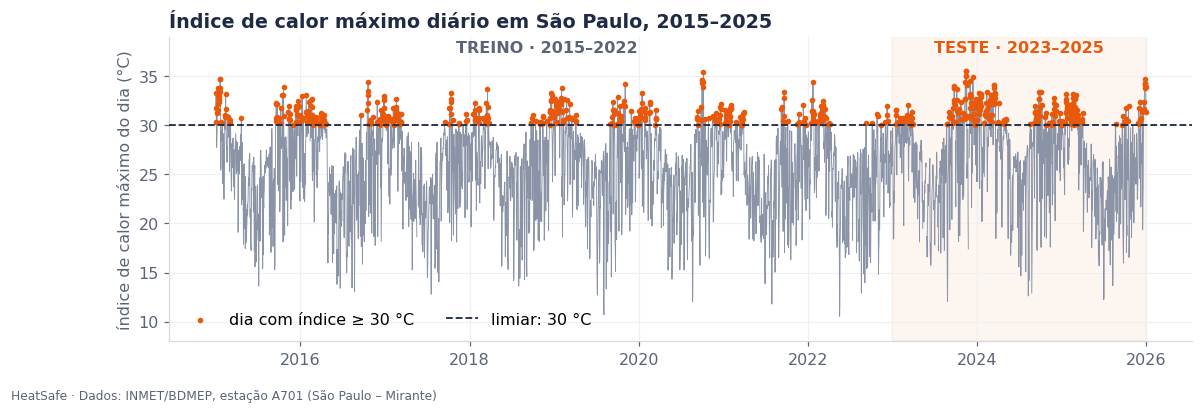

In [8]:
# Figura 2: a série completa, o limiar e a divisão treino/teste
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(ic.index, ic.values, color=CINZA, lw=0.6, zorder=2)
quentes = ic[ic >= 30]
ax.scatter(quentes.index, quentes.values, s=7, color=LARANJA, zorder=3, label="dia com índice ≥ 30 °C")
ax.axhline(30, color=TINTA, ls="--", lw=1.2, zorder=4, label="limiar: 30 °C")
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2025-12-31"), color=LARANJA, alpha=0.06, zorder=0)
ax.text(pd.Timestamp("2018-12-01"), 37.4, "TREINO · 2015–2022", ha="center", color=TINTA2, fontweight="bold")
ax.text(pd.Timestamp("2024-07-01"), 37.4, "TESTE · 2023–2025", ha="center", color=LARANJA, fontweight="bold")
ax.set_ylim(8, 39); ax.set_ylabel("índice de calor máximo do dia (°C)")
ax.set_title("Índice de calor máximo diário em São Paulo, 2015–2025")
ax.legend(loc="lower left", ncol=2)
finalizar(fig, "fig02_serie_e_divisao_treino_teste.png")

## 4. Escolha do modelo

### 4.1 Dois candidatos de árvores: XGBoost e Random Forest

Nossos dados são uma **tabela** (~2.900 dias de treino × 30 atributos) com relações **não lineares**: o mesmo calor pesa mais com umidade alta e no verão. Para esse formato, os comitês de árvores de decisão são a escolha natural. Por isso levamos dois candidatos da lista da disciplina até o fim:

| | **XGBoost** (boosting) | **Random Forest** (bagging) |
|---|---|---|
| Como funciona | Árvores em sequência, cada uma corrige os erros da anterior | Centenas de árvores independentes, cada uma com uma amostra diferente dos dados; o resultado é a média |
| Ponto forte | Menor viés: aprende padrões sutis | Menor variância: a média de muitas árvores é estável e difícil de "viciar" |
| Risco no nosso caso | Com poucos dias perigosos, pode **decorar** o treino | Pode ser menos preciso em padrões finos |
| Dados faltantes | Lida com `NaN` nativamente | Precisa preencher (usamos a mediana do treino) |
| Integração com o serviço (FastAPI) | Arquivo `.json` | Arquivo `.joblib` |

O plano inicial do grupo era o XGBoost. Em vez de escolher por preferência, **deixamos a validação cruzada decidir** (seção 5.3).

**Por que não os outros da lista?** **LSTM** precisaria de muito mais dados (temos ~2.900 dias de treino) e a memória dos dias anteriores já entra nos atributos D-1, D-2 e nas médias móveis. **KMeans + PCA** é não supervisionado, mas aqui temos o rótulo (o dia foi ou não perigoso). **MLP** exige padronização, é sensível a hiperparâmetros e é menos interpretável com tão poucos exemplos positivos.

### 4.2 Linhas de base: o modelo precisa ganhar delas

Um modelo de ML só vale a pena se for melhor do que regras simples:

1. **"Nunca avisar":** acerta ~80% dos dias (porque a maioria não é perigosa) e não protege ninguém. Mostra por que **acurácia não serve** aqui.
2. **Persistência ("amanhã será como hoje"):** avisa quando o índice de calor de hoje passa de um valor *t* (ajustado no treino). Em meteorologia, é uma linha de base difícil de bater no dia seguinte.

### 4.3 Validação cruzada temporal

`TimeSeriesSplit` com 5 dobras: cada dobra treina com o passado e valida no período seguinte. Também usamos essas dobras para escolher o limiar de decisão (seção 5.3), sem nunca tocar no teste.

In [9]:
cv = TimeSeriesSplit(n_splits=5)
dobras = []
for i, (a, b) in enumerate(cv.split(X_tr), 1):
    dobras.append({"dobra": i, "treina até": f"{data_alvo[treino][a[-1]]:%m/%Y}",
                   "valida": f"{data_alvo[treino][b[0]]:%m/%Y} a {data_alvo[treino][b[-1]]:%m/%Y}",
                   "dias perigosos no treino": int(y_tr.iloc[a].sum()), "dias perigosos na validação": int(y_tr.iloc[b].sum())})
pd.DataFrame(dobras).set_index("dobra")

,treina até,valida,dias perigosos no treino,dias perigosos na validação
dobra,,,,
1,05/2016,05/2016 a 09/2017,107,59
2,09/2017,09/2017 a 01/2019,166,62
3,01/2019,01/2019 a 05/2020,228,84
4,05/2020,05/2020 a 09/2021,312,56
5,09/2021,09/2021 a 12/2022,368,61


In [10]:
# Funções de apoio: previsões "fora da dobra" (out-of-fold) e métricas
def oof(modelo, X_, y_):
    # Treina em cada dobra do passado e prevê a dobra seguinte. Devolve as probabilidades de validação.
    partes = []
    for a, b in cv.split(X_):
        m = clone(modelo).fit(X_.iloc[a], y_.iloc[a])
        partes.append(pd.Series(m.predict_proba(X_.iloc[b])[:, 1], index=X_.index[b]))
    return pd.concat(partes)

def oof_persistencia(X_):
    return pd.concat([X_["ic_max"].iloc[b] for _, b in cv.split(X_)]).fillna(-np.inf)

def melhor_limiar(y_, score, candidatos):
    # Limiar de decisão que maximiza o F2 (recall pesa o dobro da precisão)
    f2 = [fbeta_score(y_, (score >= t).astype(int), beta=2, zero_division=0) for t in candidatos]
    return float(candidatos[int(np.argmax(f2))]), float(np.max(f2))

def metricas(y_, score, limiar, probabilidade=True):
    pred = (score >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_, pred, labels=[0, 1]).ravel()
    s = np.where(np.isfinite(score), score, np.nanmin(score[np.isfinite(score)]) - 1)
    return {"Recall": recall_score(y_, pred), "Precisão": precision_score(y_, pred, zero_division=0),
            "F1": f1_score(y_, pred), "F2": fbeta_score(y_, pred, beta=2),
            "AP (área PR)": average_precision_score(y_, s), "ROC-AUC": roc_auc_score(y_, s),
            "Brier": brier_score_loss(y_, score) if probabilidade else np.nan, "Acurácia": accuracy_score(y_, pred),
            "VP": vp, "FN": fn, "FP": fp, "VN": vn}

### 4.4 Qual limiar de "dia perigoso" o modelo consegue aprender?

Antes de investir no ajuste fino, testamos, **só com a validação cruzada no treino**, três definições de dia perigoso na estação: 30, 31 e 32 °C. Para cada uma, comparamos um XGBoost e um Random Forest com configuração padrão contra a persistência.

In [11]:
rf_padrao = make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, max_features="sqrt", random_state=SEMENTE, n_jobs=-1))
xgb_padrao = XGBClassifier(max_depth=3, learning_rate=0.03, n_estimators=300, min_child_weight=10, subsample=0.8,
                           colsample_bytree=0.8, reg_lambda=5, eval_metric="logloss", random_state=SEMENTE, n_jobs=-1)
linhas = []
for limiar_c in (30, 31, 32):
    y_l = at.montar_alvo(diario, limiar=limiar_c)[validos].astype(int)[treino]
    p_xgb = oof(xgb_padrao, X_tr, y_l); y_v = y_l.loc[p_xgb.index]
    p_rf = oof(rf_padrao, X_tr, y_l)
    p_per = oof_persistencia(X_tr)
    t_x, f2_x = melhor_limiar(y_v, p_xgb, np.arange(0.02, 0.9, 0.01))
    t_p, f2_p = melhor_limiar(y_v, p_per, np.arange(limiar_c - 4, limiar_c + 1, 0.1))
    linhas.append({"limiar (°C)": limiar_c, "dias perigosos no treino": int(y_l.sum()), "% do treino": f"{y_l.mean():.1%}",
                   "AP XGBoost": average_precision_score(y_v, p_xgb), "AP Random Forest": average_precision_score(y_v, p_rf),
                   "AP persistência": average_precision_score(y_v, p_per.clip(-100)),
                   "F2 XGBoost": f2_x, "F2 Random Forest": melhor_limiar(y_v, p_rf, np.arange(0.02, 0.9, 0.01))[1],
                   "F2 persistência": f2_p})
tab_limiar = pd.DataFrame(linhas).set_index("limiar (°C)")
melhor_ap = tab_limiar[["AP XGBoost", "AP Random Forest"]].max(axis=1)
melhor_f2 = tab_limiar[["F2 XGBoost", "F2 Random Forest"]].max(axis=1)
tab_limiar["algum modelo supera a persistência?"] = np.where((melhor_ap > tab_limiar["AP persistência"]) &
                                                             (melhor_f2 > tab_limiar["F2 persistência"]), "sim", "não")
tab_limiar.round(3)

,dias perigosos no treino,% do treino,AP XGBoost,AP Random Forest,AP persistência,F2 XGBoost,F2 Random Forest,F2 persistência,algum modelo supera a persistência?
limiar (°C),,,,,,,,,
30,429,14.7%,0.614,0.652,0.604,0.728,0.727,0.720,sim
31,203,7.0%,0.494,0.506,0.468,0.624,0.620,0.628,não
32,86,3.0%,0.294,0.300,0.314,0.508,0.509,0.549,não


**Decisão (tomada só com o treino):** com **32 °C** sobram apenas **86 dias perigosos** em 8 anos de treino, e os modelos não aprendem mais do que "hoje está quente, amanhã também estará" e não superam a persistência. Com **30 °C** há cerca de 5 vezes mais exemplos e os modelos passam a superar a persistência nas duas métricas. Como a estação mede menos calor do que o interior de uma casa de fibrocimento, 30 °C na estação também é o gatilho mais prudente para proteger a Dona Maria. **Seguimos com 30 °C.**

## 5. Treino com diferentes hiperparâmetros

Os dois candidatos passam pelo mesmo processo: **busca em grade** com a validação cruzada temporal de 5 dobras, sempre só com o treino.

**Métrica de escolha:** *Average Precision* (AP, a área sob a curva precisão × recall). Ela é adequada para classes desbalanceadas porque não depende de um limiar fixo e ignora os acertos fáceis ("dia de inverno não é perigoso"). Também registramos o ROC-AUC e o AP **no próprio treino**, para enxergar o overfitting.

### 5.1 XGBoost: 36 combinações de 3 hiperparâmetros

| Hiperparâmetro | O que controla | Valores testados |
|---|---|---|
| `max_depth` | Profundidade de cada árvore (quanta interação entre atributos ela aprende) | 1, 2, 3, 4 |
| `learning_rate` | Quanto cada nova árvore corrige as anteriores | 0,01 · 0,03 · 0,1 |
| `n_estimators` | Número de árvores | 100 · 300 · 600 |

4 × 3 × 3 = **36 combinações** × 5 dobras = 180 treinos. Os demais parâmetros ficam fixos e regularizados (`min_child_weight=10`, `subsample=0.8`, `colsample_bytree=0.8`, `reg_lambda=5`).

In [12]:
xgb_base = XGBClassifier(min_child_weight=10, subsample=0.8, colsample_bytree=0.8, reg_lambda=5,
                         eval_metric="logloss", random_state=SEMENTE, n_jobs=-1)
grade_xgb = {"max_depth": [1, 2, 3, 4], "learning_rate": [0.01, 0.03, 0.1], "n_estimators": [100, 300, 600]}
busca_xgb = GridSearchCV(xgb_base, grade_xgb, cv=cv, refit="ap", return_train_score=True, n_jobs=1,
                         scoring={"ap": "average_precision", "roc_auc": "roc_auc"}).fit(X_tr, y_tr)

def tabela_da_busca(busca, params):
    r = pd.DataFrame(busca.cv_results_)
    t = pd.DataFrame({p.split("__")[-1]: r[f"param_{p}"] for p in params})
    t["AP treino"], t["AP validação"], t["desvio AP val."] = r.mean_train_ap, r.mean_test_ap, r.std_test_ap
    t["ROC-AUC validação"] = r.mean_test_roc_auc
    t = t.sort_values("AP validação", ascending=False).reset_index(drop=True); t.index += 1
    return t

tabela_xgb = tabela_da_busca(busca_xgb, list(grade_xgb))
tabela_xgb.round(3).to_csv(MODELO / "grade_xgboost.csv", index_label="posicao")
print(f"XGBoost · melhor combinação: {busca_xgb.best_params_} · AP validação = {busca_xgb.best_score_:.3f}")
print(f"Pior combinação: AP validação = {tabela_xgb['AP validação'].min():.3f}  (grade completa em modelo/grade_xgboost.csv)")
tabela_xgb.head(8).round(3)

XGBoost · melhor combinação: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100} · AP validação = 0.645
Pior combinação: AP validação = 0.557  (grade completa em modelo/grade_xgboost.csv)


,max_depth,learning_rate,n_estimators,AP treino,AP validação,desvio AP val.,ROC-AUC validação
1,2,0.03,100,0.785,0.645,0.049,0.916
2,3,0.01,100,0.780,0.640,0.052,0.912
3,2,0.01,300,0.786,0.640,0.050,0.916
4,3,0.01,300,0.817,0.639,0.059,0.917
5,3,0.03,100,0.818,0.638,0.058,0.916
6,4,0.01,100,0.789,0.637,0.056,0.912
7,2,0.01,600,0.822,0.637,0.053,0.918
8,4,0.03,100,0.834,0.636,0.059,0.915


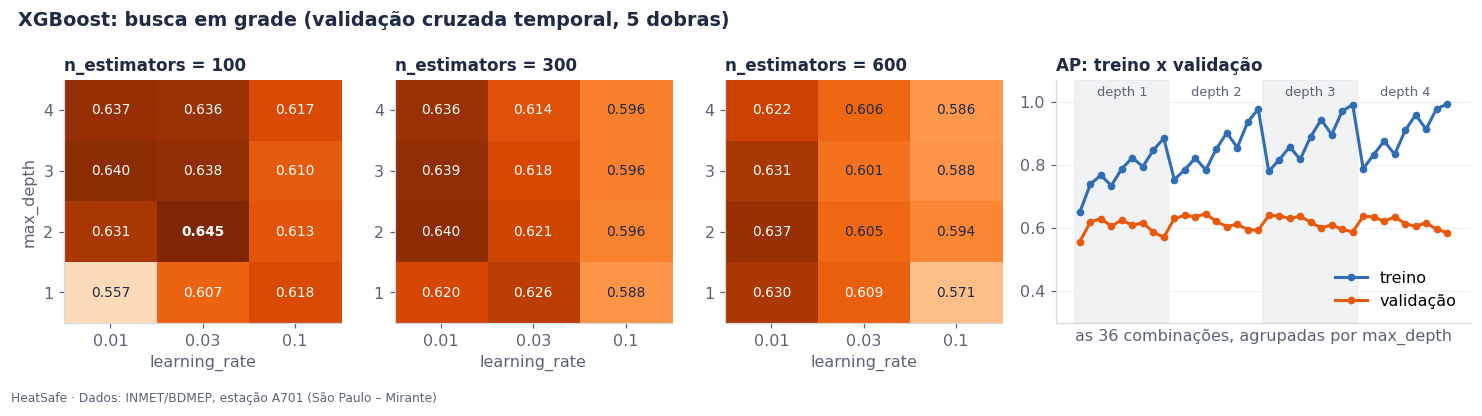

In [13]:
# Figura 3: mapa da grade do XGBoost (AP de validação) e a distância entre treino e validação
fig, eixos = plt.subplots(1, 4, figsize=(13.5, 3.5), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
vmin, vmax = tabela_xgb["AP validação"].min(), tabela_xgb["AP validação"].max()
for ax, n in zip(eixos[:3], grade_xgb["n_estimators"]):
    m = (tabela_xgb[tabela_xgb.n_estimators == n]
         .pivot(index="max_depth", columns="learning_rate", values="AP validação").sort_index(ascending=False))
    ax.imshow(m.values, cmap="Oranges", vmin=vmin - 0.02, vmax=vmax, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if v > (vmin + vmax) / 2 + 0.005 else TINTA, fontweight="bold" if np.isclose(v, vmax) else None)
    ax.set_xticks(range(3), [str(c) for c in m.columns]); ax.set_yticks(range(m.shape[0]), m.index)
    ax.set_xlabel("learning_rate"); ax.set_title(f"n_estimators = {n}", fontsize=11); ax.grid(False)
eixos[0].set_ylabel("max_depth")

ax = eixos[3]
g = tabela_xgb.sort_values(["max_depth", "learning_rate", "n_estimators"]).reset_index(drop=True)
ax.plot(g.index, g["AP treino"], color=AZUL, lw=2, marker="o", ms=4, label="treino")
ax.plot(g.index, g["AP validação"], color=LARANJA, lw=2, marker="o", ms=4, label="validação")
for d_ in grade_xgb["max_depth"]:
    idx = g.index[g.max_depth == d_]
    ax.axvspan(idx.min() - 0.5, idx.max() + 0.5, color=CINZA_CLARO if d_ % 2 else "white", alpha=0.35, zorder=0)
    ax.text(float(np.mean(idx)), 1.02, f"depth {d_}", ha="center", fontsize=8.5, color=TINTA2)
ax.set_ylim(0.3, 1.07); ax.set_xticks([]); ax.set_xlabel("as 36 combinações, agrupadas por max_depth")
ax.set_title("AP: treino x validação", fontsize=11); ax.legend(loc="lower right")
fig.suptitle("XGBoost: busca em grade (validação cruzada temporal, 5 dobras)", x=0.01, ha="left",
             fontweight="bold", color=TINTA, fontsize=12.5)
fig.tight_layout()
finalizar(fig, "fig03_grade_xgboost.png")

**Leitura:** quanto mais profundas as árvores e maior o `learning_rate`, mais o XGBoost **decora o treino** (AP de treino perto de 1,0) sem ganhar na validação. As melhores combinações são as **rasas e lentas**: com poucos dias perigosos, o modelo precisa de regras simples.

### 5.2 Random Forest: 30 combinações de 3 hiperparâmetros

| Hiperparâmetro | O que controla | Valores testados |
|---|---|---|
| `max_depth` | Profundidade máxima de cada árvore | 4, 6, 8, 12, sem limite |
| `min_samples_leaf` | Mínimo de dias em cada folha (regras baseadas em poucos dias são frágeis) | 1, 5, 20 |
| `max_features` | Fração dos atributos sorteada a cada divisão (diversidade entre as árvores) | √30 ≈ 5 atributos · 50% |

5 × 3 × 2 = **30 combinações** × 5 dobras = 150 treinos, com 300 árvores cada. Os valores faltantes são preenchidos com a **mediana do treino** (dentro do *pipeline*, ou seja, recalculada em cada dobra, sem vazar informação da validação).

In [14]:
rf_base = make_pipeline(SimpleImputer(strategy="median"),
                        RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1))
grade_rf = {"randomforestclassifier__max_depth": [4, 6, 8, 12, None],
            "randomforestclassifier__min_samples_leaf": [1, 5, 20],
            "randomforestclassifier__max_features": ["sqrt", 0.5]}
busca_rf = GridSearchCV(rf_base, grade_rf, cv=cv, refit="ap", return_train_score=True, n_jobs=1,
                        scoring={"ap": "average_precision", "roc_auc": "roc_auc"}).fit(X_tr, y_tr)
tabela_rf = tabela_da_busca(busca_rf, list(grade_rf))
tabela_rf["max_depth"] = tabela_rf["max_depth"].astype(object).where(tabela_rf["max_depth"].notna(), "sem limite")
tabela_rf.round(3).to_csv(MODELO / "grade_random_forest.csv", index_label="posicao")
melhor_rf = {k.split("__")[1]: v for k, v in busca_rf.best_params_.items()}
print(f"Random Forest · melhor combinação: {melhor_rf} · AP validação = {busca_rf.best_score_:.3f}")
print(f"Pior combinação: AP validação = {tabela_rf['AP validação'].min():.3f}  (grade completa em modelo/grade_random_forest.csv)")
tabela_rf.head(8).round(3)

Random Forest · melhor combinação: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 5} · AP validação = 0.668
Pior combinação: AP validação = 0.640  (grade completa em modelo/grade_random_forest.csv)


,max_depth,min_samples_leaf,max_features,AP treino,AP validação,desvio AP val.,ROC-AUC validação
1,8,5,sqrt,0.951,0.668,0.053,0.920
2,6,5,sqrt,0.913,0.667,0.054,0.919
3,sem limite,5,sqrt,0.965,0.666,0.051,0.919
4,12,5,sqrt,0.965,0.665,0.052,0.919
5,4,1,sqrt,0.847,0.664,0.056,0.917
6,6,1,sqrt,0.951,0.663,0.052,0.917
7,6,20,sqrt,0.820,0.663,0.061,0.919
8,4,5,sqrt,0.835,0.663,0.055,0.917


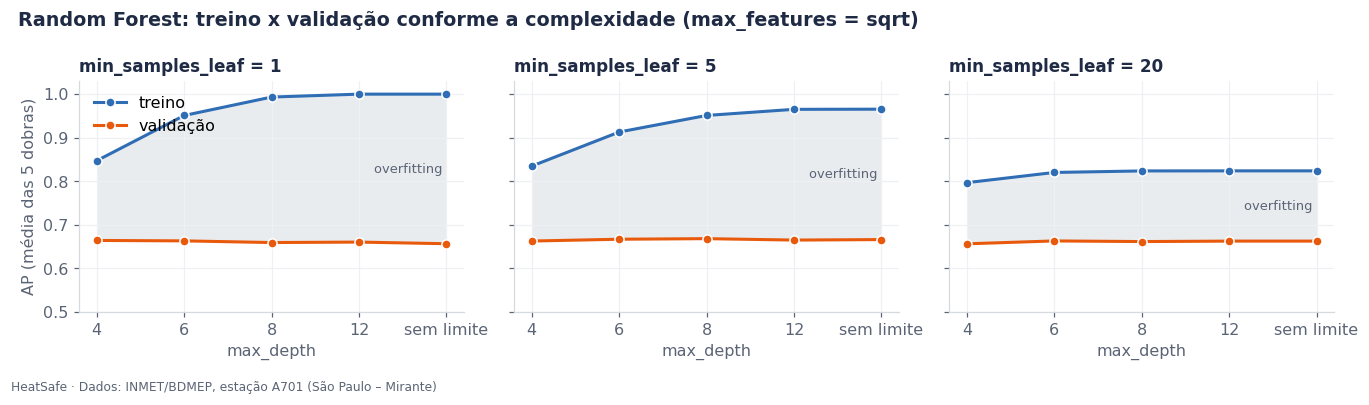

In [15]:
# Figura 4: curva de validação do Random Forest (overfitting conforme a árvore fica mais complexa)
mf = melhor_rf["max_features"]
ordem = [4, 6, 8, 12, "sem limite"]
fig, eixos = plt.subplots(1, 3, figsize=(12.5, 3.4), sharey=True)
for ax, folha in zip(eixos, [1, 5, 20]):
    s = tabela_rf[(tabela_rf.min_samples_leaf == folha) & (tabela_rf.max_features.astype(str) == str(mf))]
    s = s.set_index("max_depth").reindex(ordem)
    xs = range(len(ordem))
    ax.plot(xs, s["AP treino"], color=AZUL, lw=2, marker="o", ms=6, mec="white", label="treino")
    ax.plot(xs, s["AP validação"], color=LARANJA, lw=2, marker="o", ms=6, mec="white", label="validação")
    ax.fill_between(xs, s["AP validação"], s["AP treino"], color=CINZA_CLARO, alpha=0.5, lw=0)
    ax.text(len(ordem) - 1, (s["AP treino"].iloc[-1] + s["AP validação"].iloc[-1]) / 2, "overfitting ",
            ha="right", va="center", fontsize=8.5, color=TINTA2)
    ax.set_xticks(list(xs), [str(o) for o in ordem]); ax.set_xlabel("max_depth")
    ax.set_title(f"min_samples_leaf = {folha}", fontsize=11)
eixos[0].set_ylabel("AP (média das 5 dobras)"); eixos[0].legend(loc="upper left"); eixos[0].set_ylim(0.5, 1.03)
fig.suptitle(f"Random Forest: treino x validação conforme a complexidade (max_features = {mf})", x=0.01, ha="left",
             fontweight="bold", color=TINTA, fontsize=12.5)
fig.tight_layout()
finalizar(fig, "fig04_validacao_random_forest.png")

**Leitura:** com folhas de 1 dia e árvores sem limite, o Random Forest chega a AP ≈ 1,0 no treino (decorou cada dia), mas a validação não acompanha. Folhas maiores (`min_samples_leaf`) funcionam como freio: a distância entre as curvas diminui.

### 5.3 Qual modelo generaliza melhor? Comparação dobra a dobra

Comparamos a melhor combinação de cada candidato **nas mesmas 5 dobras**, junto com a persistência. Ganhar na média e na maioria das dobras indica uma vantagem consistente, não sorte.

In [16]:
def ap_por_dobra(busca):
    return [busca.cv_results_[f"split{k}_test_ap"][busca.best_index_] for k in range(cv.n_splits)]

ap_per = [average_precision_score(y_tr.iloc[b], X_tr["ic_max"].iloc[b].fillna(-100)) for _, b in cv.split(X_tr)]
por_dobra = pd.DataFrame({"XGBoost": ap_por_dobra(busca_xgb), "Random Forest": ap_por_dobra(busca_rf),
                          "Persistência": ap_per}, index=[r["valida"] for r in dobras])
por_dobra.index.name = "dobra de validação"
por_dobra.loc["MÉDIA"] = por_dobra.mean()

# previsões fora da dobra das duas melhores versões (usadas também para escolher o limiar)
p_oof_xgb, p_oof_rf = oof(busca_xgb.best_estimator_, X_tr, y_tr), oof(busca_rf.best_estimator_, X_tr, y_tr)
y_oof = y_tr.loc[p_oof_xgb.index]
candidatos = np.round(np.arange(0.02, 0.9, 0.01), 2)
LIMIAR_XGB, f2_xgb = melhor_limiar(y_oof, p_oof_xgb, candidatos)
LIMIAR_RF, f2_rf = melhor_limiar(y_oof, p_oof_rf, candidatos)
LIMIAR_PER, f2_per = melhor_limiar(y_oof, oof_persistencia(X_tr), np.round(np.arange(26, 31.01, 0.1), 1))

vitorias = int((por_dobra.iloc[:-1]["Random Forest"] > por_dobra.iloc[:-1]["XGBoost"]).sum())
print(f"Random Forest vence o XGBoost em {vitorias} de {cv.n_splits} dobras.")
print(f"F2 no melhor limiar (fora da dobra): XGBoost {f2_xgb:.3f} · Random Forest {f2_rf:.3f} · persistência {f2_per:.3f}")
print(f"Brier (qualidade da probabilidade):   XGBoost {brier_score_loss(y_oof, p_oof_xgb):.3f} · Random Forest {brier_score_loss(y_oof, p_oof_rf):.3f}")
por_dobra.round(3)

Random Forest vence o XGBoost em 3 de 5 dobras.
F2 no melhor limiar (fora da dobra): XGBoost 0.727 · Random Forest 0.723 · persistência 0.720
Brier (qualidade da probabilidade):   XGBoost 0.072 · Random Forest 0.070


,XGBoost,Random Forest,Persistência
dobra de validação,,,
05/2016 a 09/2017,0.619,0.699,0.711
09/2017 a 01/2019,0.578,0.569,0.589
01/2019 a 05/2020,0.706,0.704,0.586
05/2020 a 09/2021,0.626,0.660,0.595
09/2021 a 12/2022,0.699,0.709,0.608
MÉDIA,0.645,0.668,0.618


In [17]:
# Escolha: o candidato com maior AP médio na validação cruzada (critério definido antes de olhar o teste)
MODELO_ESCOLHIDO = "Random Forest" if busca_rf.best_score_ > busca_xgb.best_score_ else "XGBoost"
modelo = (busca_rf if MODELO_ESCOLHIDO == "Random Forest" else busca_xgb).best_estimator_
LIMIAR = LIMIAR_RF if MODELO_ESCOLHIDO == "Random Forest" else LIMIAR_XGB
p_oof = p_oof_rf if MODELO_ESCOLHIDO == "Random Forest" else p_oof_xgb
print(f"Modelo escolhido: {MODELO_ESCOLHIDO}")

Modelo escolhido: Random Forest


**Decisão:** o **Random Forest** tem o maior AP médio, vence o XGBoost na maioria das dobras e entrega probabilidades melhores (Brier menor). Faz sentido: com poucos dias perigosos e rótulos "no limite" (um dia de 29,9 °C e outro de 30,1 °C são quase iguais), a **média de centenas de árvores independentes** é mais estável do que árvores em sequência que tentam corrigir cada erro. O XGBoost era o plano inicial do grupo; **trocamos porque os dados mostraram que o Random Forest generaliza melhor.** O XGBoost segue no relatório como comparação.

### 5.4 Desbalanceamento: pesar a classe rara ou ajustar o limiar?

Só ~15% dos dias de treino são perigosos. Uma opção comum é dar **mais peso** a esses dias no treino (`class_weight`). A outra é manter os pesos e **ajustar o limiar de decisão**. Testamos as duas no modelo escolhido:

In [18]:
if MODELO_ESCOLHIDO == "Random Forest":
    opcoes = [("sem peso", {"randomforestclassifier__class_weight": None}),
              ("balanced", {"randomforestclassifier__class_weight": "balanced"}),
              ("balanced_subsample", {"randomforestclassifier__class_weight": "balanced_subsample"})]
else:
    razao = (y_tr == 0).sum() / (y_tr == 1).sum()
    opcoes = [("sem peso", {"scale_pos_weight": 1.0}), ("√razão", {"scale_pos_weight": np.sqrt(razao)}),
              ("razão", {"scale_pos_weight": razao})]
linhas = []
for nome, params in opcoes:
    p = oof(clone(modelo).set_params(**params), X_tr, y_tr)
    t, f2 = melhor_limiar(y_oof, p, np.arange(0.02, 0.95, 0.01))
    linhas.append({"peso da classe rara": nome, "AP validação": average_precision_score(y_oof, p),
                   "F2 no melhor limiar": f2, "Brier (erro da probabilidade)": brier_score_loss(y_oof, p)})
pd.DataFrame(linhas).set_index("peso da classe rara").round(3)

,AP validação,F2 no melhor limiar,Brier (erro da probabilidade)
peso da classe rara,,,
sem peso,0.654,0.723,0.070
balanced,0.644,0.734,0.083
balanced_subsample,0.643,0.729,0.084


O peso extra **não melhora** a capacidade de separar os dias (AP e F2 praticamente iguais ou piores) e **piora as probabilidades** (Brier maior): o modelo passa a dizer "70%" quando a chance real é bem menor. Como o serviço de previsão devolve uma **probabilidade** para a API (`"probabilidade": 0.87` no contrato), mantemos o treino **sem peso** e tratamos o desbalanceamento escolhendo o **limiar de decisão**.

### 5.5 Limiar de decisão: quando ligar o modo vigilância

Com as previsões *fora da dobra* do treino, escolhemos a probabilidade a partir da qual o HeatSafe liga o modo vigilância. O critério é o maior **F2** (recall pesa o dobro). O limiar da persistência foi escolhido do mesmo jeito, para a comparação ser justa.

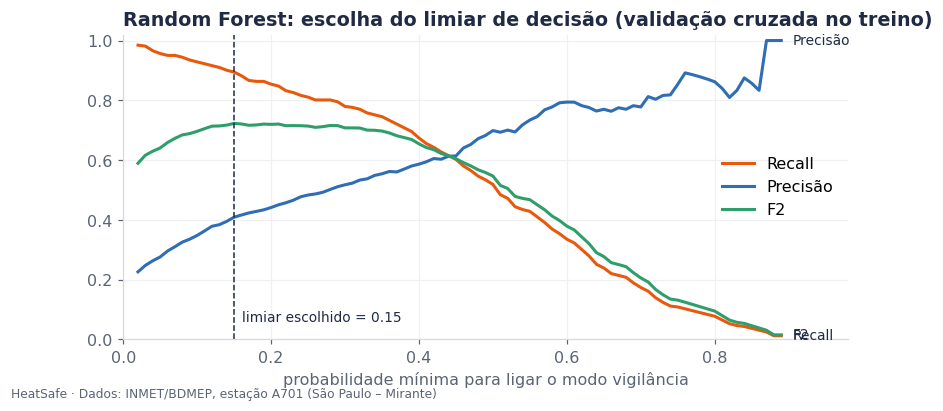

Random Forest: liga o modo vigilância quando P(amanhã perigoso) >= 0.15
Persistência: avisa quando o índice de calor de hoje (até 18h) >= 28.6 °C


In [19]:
curva = pd.DataFrame([{"limiar": t, "Recall": recall_score(y_oof, p_oof >= t),
                       "Precisão": precision_score(y_oof, p_oof >= t, zero_division=0),
                       "F2": fbeta_score(y_oof, p_oof >= t, beta=2)} for t in candidatos])
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for col, cor in [("Recall", LARANJA), ("Precisão", AZUL), ("F2", VERDE)]:
    ax.plot(curva.limiar, curva[col], color=cor, lw=2, label=col)
    ax.text(0.905, curva[col].iloc[-1], col, color=TINTA, va="center", fontsize=9)
ax.axvline(LIMIAR, color=TINTA, ls="--", lw=1)
ax.text(LIMIAR + 0.01, 0.06, f"limiar escolhido = {LIMIAR:.2f}", color=TINTA, fontsize=9)
ax.set_xlim(0, 0.98); ax.set_ylim(0, 1.02); ax.set_xlabel("probabilidade mínima para ligar o modo vigilância")
ax.set_title(f"{MODELO_ESCOLHIDO}: escolha do limiar de decisão (validação cruzada no treino)"); ax.legend(loc="center right")
finalizar(fig, "fig05_escolha_do_limiar.png")
print(f"{MODELO_ESCOLHIDO}: liga o modo vigilância quando P(amanhã perigoso) >= {LIMIAR:.2f}")
print(f"Persistência: avisa quando o índice de calor de hoje (até 18h) >= {LIMIAR_PER:.1f} °C")

## 6. Resultados em treino e teste

O modelo escolhido é treinado em **todo o período de treino** (2015–2022) e avaliado, pela primeira e única vez, no **teste** (2023–2025).

### 6.1 Treino e teste lado a lado

In [20]:
p_tr = modelo.predict_proba(X_tr)[:, 1]
p_te = modelo.predict_proba(X_te)[:, 1]
lado_a_lado = pd.DataFrame({"Treino (2015–2022)": metricas(y_tr, p_tr, LIMIAR),
                            "Validação cruzada (fora da dobra)": metricas(y_oof, p_oof.values, LIMIAR),
                            "Teste (2023–2025)": metricas(y_te, p_te, LIMIAR)})
print(f"{MODELO_ESCOLHIDO} · {melhor_rf if MODELO_ESCOLHIDO == 'Random Forest' else busca_xgb.best_params_} · limiar {LIMIAR:.2f}")
lado_a_lado.apply(lambda col: [f"{v:.0f}" if k in ("VP", "FN", "FP", "VN") else f"{v:.3f}" for k, v in col.items()])

Random Forest · {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 5} · limiar 0.15


,Treino (2015–2022),Validação cruzada (fora da dobra),Teste (2023–2025)
Recall,0.988,0.894,0.904
Precisão,0.527,0.409,0.522
F1,0.688,0.561,0.662
F2,0.841,0.723,0.788
AP (área PR),0.923,0.654,0.774
ROC-AUC,0.983,0.921,0.917
Brier,0.042,0.070,0.095
Acurácia,0.868,0.814,0.796
VP,424,288,216
FN,5,34,23


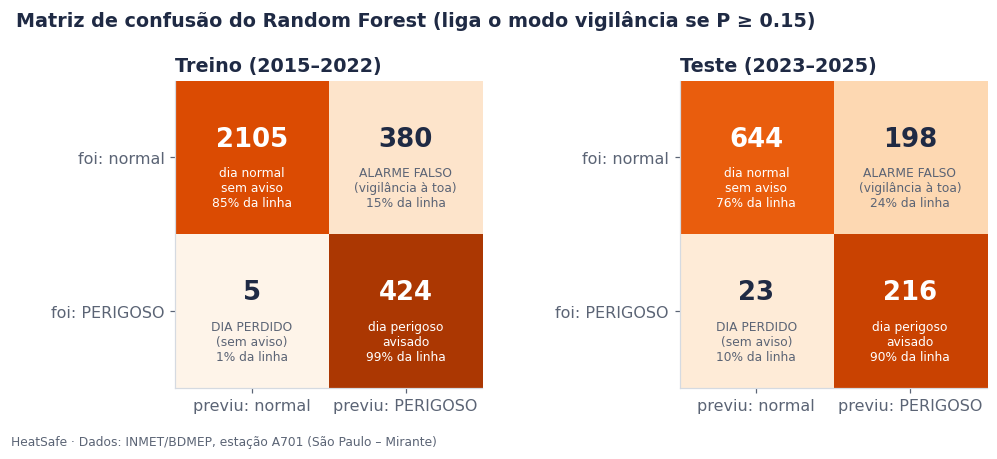

In [21]:
# Figura 6: matrizes de confusão em treino e teste
fig, eixos = plt.subplots(1, 2, figsize=(9.5, 3.9))
for ax, (nome, yy, pp) in zip(eixos, [("Treino (2015–2022)", y_tr, p_tr), ("Teste (2023–2025)", y_te, p_te)]):
    cm = confusion_matrix(yy, (pp >= LIMIAR).astype(int), labels=[0, 1])
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Oranges", vmin=0, vmax=1.15)
    rotulos = [["dia normal\nsem aviso", "ALARME FALSO\n(vigilância à toa)"],
               ["DIA PERDIDO\n(sem aviso)", "dia perigoso\navisado"]]
    for i in range(2):
        for j in range(2):
            frac = cm[i, j] / cm[i].sum()
            ax.text(j, i - 0.12, f"{cm[i, j]}", ha="center", va="center", fontsize=17, fontweight="bold",
                    color="white" if frac > 0.6 else TINTA)
            ax.text(j, i + 0.2, rotulos[i][j] + f"\n{frac:.0%} da linha", ha="center", va="center", fontsize=8,
                    color="white" if frac > 0.6 else TINTA2)
    ax.set_xticks([0, 1], ["previu: normal", "previu: PERIGOSO"]); ax.set_yticks([0, 1], ["foi: normal", "foi: PERIGOSO"])
    ax.set_title(nome); ax.grid(False)
fig.suptitle(f"Matriz de confusão do {MODELO_ESCOLHIDO} (liga o modo vigilância se P ≥ {LIMIAR:.2f})", x=0.01, ha="left",
             fontweight="bold", color=TINTA, fontsize=12.5)
fig.tight_layout()
finalizar(fig, "fig06_matrizes_de_confusao.png")

### 6.2 Overfitting: o modelo decorou o treino?

Comparar com o **treino** mede quanto o modelo decorou. Comparar com a **validação cruzada** mede se a nossa estimativa (feita só com dados de treino) foi honesta.

In [22]:
gap = lado_a_lado.loc[["Recall", "Precisão", "F2", "AP (área PR)", "ROC-AUC", "Brier"]].astype(float)
gap["treino − teste"] = gap["Treino (2015–2022)"] - gap["Teste (2023–2025)"]
gap["validação − teste"] = gap["Validação cruzada (fora da dobra)"] - gap["Teste (2023–2025)"]
gap.round(3)

,Treino (2015–2022),Validação cruzada (fora da dobra),Teste (2023–2025),treino − teste,validação − teste
Recall,0.988,0.894,0.904,0.085,-0.009
Precisão,0.527,0.409,0.522,0.006,-0.113
F2,0.841,0.723,0.788,0.053,-0.065
AP (área PR),0.923,0.654,0.774,0.150,-0.120
ROC-AUC,0.983,0.921,0.917,0.067,0.005
Brier,0.042,0.070,0.095,-0.052,-0.025


**Leitura do overfitting:**
- **Treino × teste:** no treino o Random Forest pega 99% dos dias perigosos (AP 0,92); no teste, 90% (AP 0,77). Essa diferença é típica do Random Forest, porque cada árvore já "viu" a maior parte dos dias de treino. Por isso o número de treino **não** serve como estimativa, e quem cumpre esse papel é a validação cruzada.
- **Validação × teste:** o **ROC-AUC**, que não depende da proporção de dias perigosos, ficou praticamente igual (0,921 na validação, 0,917 no teste). A validação cruzada **previu corretamente** o desempenho em dados novos.
- **Por que AP e precisão subiram no teste?** No teste, 22% dos dias são perigosos (contra 15% no treino). Com mais dias positivos, é natural que mais avisos se confirmem. Não é o modelo "melhorando": é o clima mais quente de 2023–2025.
- **Controle do overfitting:** a busca escolheu `min_samples_leaf = 5` e `max_depth = 8`, que limitam regras baseadas em pouquíssimos dias (figura 4), e a escolha do limiar foi feita fora da dobra.

### 6.3 Comparação com as linhas de base no teste

In [23]:
per_te = X_te["ic_max"].fillna(-np.inf).values
p_xgb_te = busca_xgb.best_estimator_.predict_proba(X_te)[:, 1]
p_rf_te = busca_rf.best_estimator_.predict_proba(X_te)[:, 1]
marca = lambda nome: nome + " (HeatSafe)" if nome == MODELO_ESCOLHIDO else nome
comparacao = pd.DataFrame({
    "Nunca avisar": metricas(y_te, np.zeros(len(y_te)), 0.5),
    f"Persistência (hoje ≥ {LIMIAR_PER:.1f} °C)": metricas(y_te, per_te, LIMIAR_PER, probabilidade=False),
    marca("XGBoost"): metricas(y_te, p_xgb_te, LIMIAR_XGB),
    marca("Random Forest"): metricas(y_te, p_rf_te, LIMIAR_RF),
}).T
comparacao.loc["Nunca avisar", ["AP (área PR)", "ROC-AUC"]] = [y_te.mean(), 0.5]
comparacao["alarmes falsos por ano"] = comparacao["FP"] / 3
comparacao = comparacao.astype({"VP": int, "FN": int, "FP": int, "VN": int})
comparacao.round(3)

,Recall,Precisão,F1,F2,AP (área PR),ROC-AUC,Brier,Acurácia,VP,FN,FP,VN,alarmes falsos por ano
Nunca avisar,0.000,0.000,0.000,0.000,0.221,0.500,0.221,0.779,0,239,0,842,0.000
Persistência (hoje ≥ 28.6 °C),0.883,0.551,0.678,0.788,0.713,0.897,NaN,0.815,211,28,172,670,57.333
XGBoost,0.782,0.607,0.684,0.740,0.752,0.916,0.098,0.840,187,52,121,721,40.333
Random Forest (HeatSafe),0.904,0.522,0.662,0.788,0.774,0.917,0.095,0.796,216,23,198,644,66.000


**Leitura:**
- **"Nunca avisar"** tem 78% de acurácia e não protege ninguém. Por isso a acurácia não é a métrica deste problema.
- A **persistência** é forte: o calor de hoje é, de longe, o melhor indício do calor de amanhã, como confirma a importância dos atributos (seção 6.4).
- O **Random Forest** tem a melhor capacidade de **ordenar** os dias por risco (maior AP e ROC-AUC). No ponto de operação escolhido, avisa 5 dias perigosos a mais do que a persistência, ao custo de 26 alarmes falsos a mais em 3 anos. A vantagem mais útil é a **probabilidade calibrada**, que a regra simples não oferece e que permite graduar o alerta (seção 6.6).
- O **XGBoost** fica com o menor número de alarmes falsos, mas perde 52 dias perigosos, mais do que o dobro do Random Forest. Para a Dona Maria, perder um dia perigoso é o pior erro.

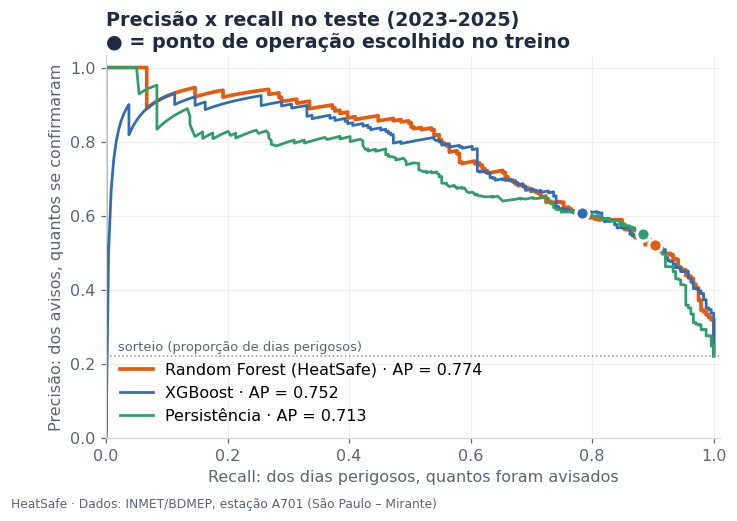

In [24]:
# Figura 7: curva precisão x recall no teste
outro = "XGBoost" if MODELO_ESCOLHIDO == "Random Forest" else "Random Forest"
series = {MODELO_ESCOLHIDO: (p_rf_te if MODELO_ESCOLHIDO == "Random Forest" else p_xgb_te, LARANJA, LIMIAR),
          outro: (p_xgb_te if outro == "XGBoost" else p_rf_te, AZUL, LIMIAR_XGB if outro == "XGBoost" else LIMIAR_RF),
          "Persistência": (np.where(np.isfinite(per_te), per_te, 0), VERDE, LIMIAR_PER)}
fig, ax = plt.subplots(figsize=(7.2, 4.5))
for nome, (score, cor, lim) in series.items():
    pr, rc, _ = precision_recall_curve(y_te, score)
    ax.plot(rc, pr, color=cor, lw=2.4 if cor == LARANJA else 1.8, label=f"{marca(nome)} · AP = {average_precision_score(y_te, score):.3f}")
    ponto = (score >= lim).astype(int)
    ax.scatter(recall_score(y_te, ponto), precision_score(y_te, ponto), s=75, color=cor, edgecolor="white", lw=2, zorder=5)
ax.axhline(y_te.mean(), color=CINZA, ls=":", lw=1)
ax.text(0.02, y_te.mean() + 0.015, "sorteio (proporção de dias perigosos)", fontsize=8.5, color=TINTA2)
ax.set_xlabel("Recall: dos dias perigosos, quantos foram avisados"); ax.set_ylabel("Precisão: dos avisos, quantos se confirmaram")
ax.set_xlim(0, 1.01); ax.set_ylim(0, 1.03)
ax.set_title("Precisão x recall no teste (2023–2025)\n● = ponto de operação escolhido no treino")
ax.legend(loc="lower left")
finalizar(fig, "fig07_curva_precisao_recall_teste.png")

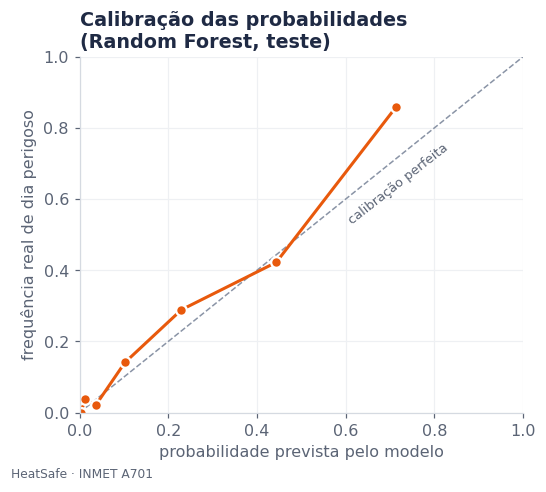

Brier no teste: 0.095  (referência 'sempre a média do treino': 0.178)
Probabilidade média prevista no teste: 19.3% · frequência real: 22.1%


In [25]:
# Figura 8: as probabilidades são confiáveis? (calibração no teste)
frac, media = calibration_curve(y_te, p_te, n_bins=8, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot([0, 1], [0, 1], color=CINZA, ls="--", lw=1)
ax.text(0.6, 0.53, "calibração perfeita", rotation=38, color=TINTA2, fontsize=8.5)
ax.plot(media, frac, color=LARANJA, lw=2, marker="o", ms=7, mec="white", mew=1.5)
ax.set_xlabel("probabilidade prevista pelo modelo"); ax.set_ylabel("frequência real de dia perigoso")
ax.set_title(f"Calibração das probabilidades\n({MODELO_ESCOLHIDO}, teste)"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
finalizar(fig, "fig08_calibracao_teste.png", fonte="HeatSafe · INMET A701")
print(f"Brier no teste: {brier_score_loss(y_te, p_te):.3f}  (referência 'sempre a média do treino': "
      f"{brier_score_loss(y_te, np.full(len(y_te), y_tr.mean())):.3f})")
print(f"Probabilidade média prevista no teste: {p_te.mean():.1%} · frequência real: {y_te.mean():.1%}")

### 6.4 O que o modelo olha?

A **importância por permutação** mede quanto o AP no teste cai quando embaralhamos um atributo. Quanto maior a queda, mais o modelo depende dele.

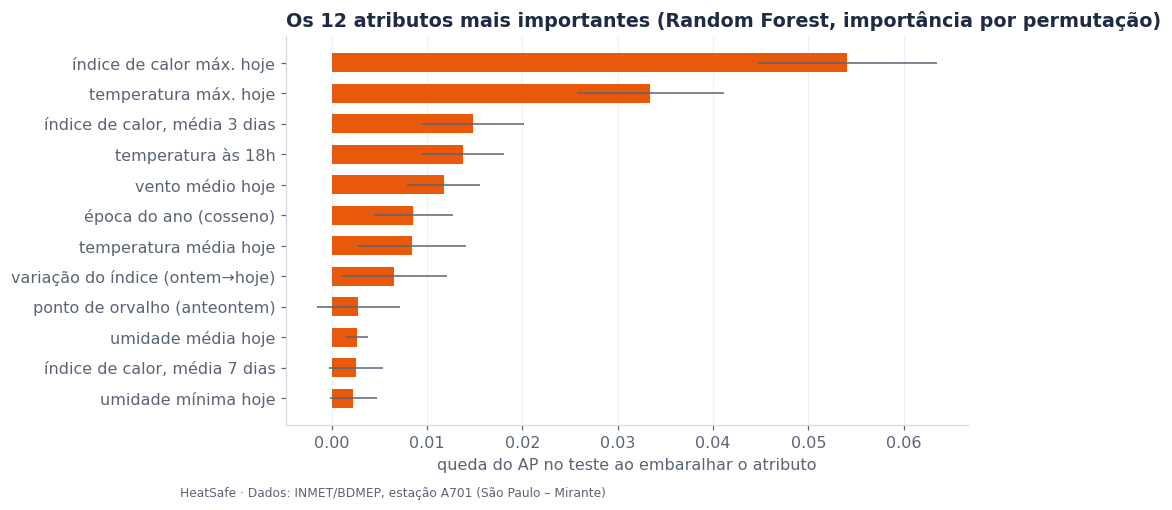

,queda média do AP,desvio
ic_max,0.0541,0.0094
temp_max,0.0334,0.0077
ic_max_media3,0.0148,0.0054
temp_18h,0.0137,0.0043
vento_medio,0.0117,0.0038
doy_cos,0.0085,0.0041
temp_media,0.0084,0.0057
delta_ic,0.0065,0.0056


In [26]:
imp = permutation_importance(modelo, X_te, y_te, scoring="average_precision", n_repeats=15, random_state=SEMENTE, n_jobs=1)
imp = pd.DataFrame({"queda média do AP": imp.importances_mean, "desvio": imp.importances_std}, index=X_te.columns)
imp = imp.sort_values("queda média do AP", ascending=False)
top = imp.head(12).iloc[::-1]
nomes = {"ic_max": "índice de calor máx. hoje", "temp_max": "temperatura máx. hoje", "temp_media": "temperatura média hoje",
         "temp_min": "temperatura mín. hoje", "temp_18h": "temperatura às 18h", "umid_media": "umidade média hoje",
         "umid_min": "umidade mínima hoje", "orvalho_medio": "ponto de orvalho hoje", "pressao_media": "pressão média hoje",
         "pressao_18h": "pressão às 18h", "radiacao_total": "radiação solar hoje", "chuva": "chuva hoje", "vento_medio": "vento médio hoje",
         "ic_max_media3": "índice de calor, média 3 dias", "ic_max_media7": "índice de calor, média 7 dias",
         "delta_ic": "variação do índice (ontem→hoje)", "delta_pressao": "variação da pressão (ontem→hoje)",
         "mes": "mês", "doy_sin": "época do ano (seno)", "doy_cos": "época do ano (cosseno)"}
def rot(c):
    if c[-3:] in ("_d1", "_d2"):
        return nomes.get(c[:-3], c[:-3]).replace(" hoje", "") + (" (ontem)" if c.endswith("_d1") else " (anteontem)")
    return nomes.get(c, c)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh([rot(c) for c in top.index], top["queda média do AP"], xerr=top["desvio"], color=LARANJA, height=0.62,
        error_kw={"ecolor": TINTA2, "lw": 1}, zorder=3)
ax.set_xlabel("queda do AP no teste ao embaralhar o atributo"); ax.grid(axis="y", visible=False)
ax.set_title(f"Os 12 atributos mais importantes ({MODELO_ESCOLHIDO}, importância por permutação)")
finalizar(fig, "fig09_importancia_atributos.png")
imp.head(8).round(4)

### 6.5 O modelo no calendário: 2023 a 2025

Cada ponto é um dia do teste. **Laranja:** dia perigoso avisado na véspera. **Azul (×):** dia perigoso que o modelo deixou passar. **Cinza vazado:** alarme falso.

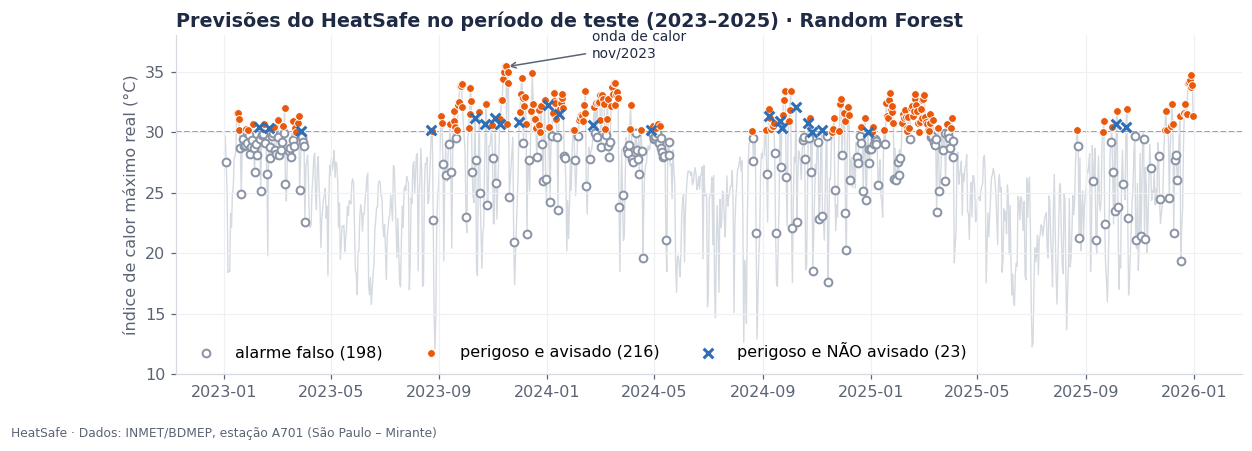

In [27]:
teste_df = pd.DataFrame({"ic_real": diario["indice_calor_max_c"].reindex(data_alvo[teste]).values,
                         "prob": p_te, "alvo": y_te.values}, index=data_alvo[teste])
teste_df["aviso"] = (teste_df.prob >= LIMIAR).astype(int)
vp = teste_df[(teste_df.alvo == 1) & (teste_df.aviso == 1)]
fn = teste_df[(teste_df.alvo == 1) & (teste_df.aviso == 0)]
fp = teste_df[(teste_df.alvo == 0) & (teste_df.aviso == 1)]

fig, ax = plt.subplots(figsize=(12.5, 4))
ax.plot(teste_df.index, teste_df.ic_real, color=CINZA_CLARO, lw=0.9, zorder=1)
ax.axhline(30, color=LARANJA, ls="--", lw=1, zorder=1)
ax.scatter(fp.index, fp.ic_real, s=26, facecolor="white", edgecolor=CINZA, lw=1.3, zorder=3, label=f"alarme falso ({len(fp)})")
ax.scatter(vp.index, vp.ic_real, s=26, color=LARANJA, edgecolor="white", lw=0.6, zorder=4, label=f"perigoso e avisado ({len(vp)})")
ax.scatter(fn.index, fn.ic_real, s=40, color=AZUL, marker="x", lw=2, zorder=5, label=f"perigoso e NÃO avisado ({len(fn)})")
ax.annotate("onda de calor\nnov/2023", xy=(pd.Timestamp("2023-11-15"), 35.4), xytext=(pd.Timestamp("2024-02-20"), 36.2),
            fontsize=9, color=TINTA, arrowprops={"arrowstyle": "->", "color": TINTA2})
ax.set_ylim(10, 38); ax.set_ylabel("índice de calor máximo real (°C)")
ax.set_title(f"Previsões do HeatSafe no período de teste (2023–2025) · {MODELO_ESCOLHIDO}")
ax.legend(loc="lower left", ncol=3)
finalizar(fig, "fig10_calendario_teste.png")

In [28]:
onda = teste_df.loc["2023-11-08":"2023-11-20"].copy()
onda["resultado"] = np.select([(onda.alvo == 1) & (onda.aviso == 1), (onda.alvo == 1) & (onda.aviso == 0),
                               (onda.alvo == 0) & (onda.aviso == 1)], ["avisou ✔", "perdeu ✘", "alarme falso"], "normal, sem aviso")
semana = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
onda.index = [f"{semana[d.dayofweek]} {d:%d/%m/%Y}" for d in onda.index]
print("Onda de calor de novembro de 2023: previsão feita às 19h da véspera de cada dia")
onda.rename(columns={"ic_real": "índice de calor real (°C)", "prob": "probabilidade prevista na véspera"})[
    ["índice de calor real (°C)", "probabilidade prevista na véspera", "resultado"]].round(2)

Onda de calor de novembro de 2023: previsão feita às 19h da véspera de cada dia


,índice de calor real (°C),probabilidade prevista na véspera,resultado
qua 08/11/2023,30.66,0.07,perdeu ✘
qui 09/11/2023,31.05,0.50,avisou ✔
sex 10/11/2023,32.67,0.60,avisou ✔
sáb 11/11/2023,32.66,0.55,avisou ✔
dom 12/11/2023,34.39,0.66,avisou ✔
seg 13/11/2023,34.94,0.66,avisou ✔
ter 14/11/2023,35.46,0.48,avisou ✔
qua 15/11/2023,35.47,0.42,avisou ✔
qui 16/11/2023,30.71,0.46,avisou ✔
sex 17/11/2023,34.96,0.36,avisou ✔


In [29]:
# Os números que vão para a conclusão
r = lado_a_lado["Teste (2023–2025)"]
per = comparacao.loc[f"Persistência (hoje ≥ {LIMIAR_PER:.1f} °C)"]
avisos = int(r.VP + r.FP)
print(f"No teste (2023–2025) houve {int(r.VP + r.FN)} dias perigosos.")
print(f"O HeatSafe avisou na véspera {int(r.VP)} deles: {r.Recall:.0%}, ou seja, cerca de {round(r.Recall * 10)} de cada 10.")
print(f"Fez {avisos} avisos; {int(r.VP)} se confirmaram: {r['Precisão']:.0%}, cerca de {round(r['Precisão'] * 10)} de cada 10 avisos.")
print(f"Alarmes falsos: {int(r.FP)} em 3 anos ({r.FP / 3:.0f} por ano, ~{r.FP / 36:.1f} por mês).")
print(f"Persistência: avisou {int(per.VP)} dias perigosos com {int(per.FP)} alarmes falsos.")
print(f"Diferença (modelo − persistência): {int(r.VP - per.VP):+d} dias perigosos avisados, {int(r.FP - per.FP):+d} alarmes falsos.")
n_onda = onda[onda.ic_real >= 30]
print(f"Onda de calor de nov/2023: {int((n_onda.resultado == 'avisou ✔').sum())} de {len(n_onda)} dias perigosos avisados na véspera.")

No teste (2023–2025) houve 239 dias perigosos.
O HeatSafe avisou na véspera 216 deles: 90%, ou seja, cerca de 9 de cada 10.
Fez 414 avisos; 216 se confirmaram: 52%, cerca de 5 de cada 10 avisos.
Alarmes falsos: 198 em 3 anos (66 por ano, ~5.5 por mês).
Persistência: avisou 211 dias perigosos com 172 alarmes falsos.
Diferença (modelo − persistência): +5 dias perigosos avisados, +26 alarmes falsos.
Onda de calor de nov/2023: 10 de 11 dias perigosos avisados na véspera.


### 6.6 Análise dos erros: onde o modelo erra?

Saber **como** o modelo erra importa tanto quanto saber quanto ele erra. Um alarme falso num dia de 29 °C é bem diferente de um alarme falso num dia de 18 °C. Um dia perdido de 30,1 °C é bem diferente de um dia perdido de 35 °C.

In [30]:
falsos, perdidos = teste_df[(teste_df.alvo == 0) & (teste_df.aviso == 1)], teste_df[(teste_df.alvo == 1) & (teste_df.aviso == 0)]
extremos = teste_df[teste_df.ic_real >= 32]
print(f"ALARMES FALSOS ({len(falsos)}): índice de calor real mediano de {falsos.ic_real.median():.1f} °C; "
      f"{(falsos.ic_real >= 27).mean():.0%} deles foram dias de nível Atenção (≥ 27 °C), ou seja, dias quentes que só não chegaram a 30 °C.")
print(f"DIAS PERDIDOS ({len(perdidos)}): {(perdidos.ic_real < 31.5).sum()} deles ficaram entre 30,0 e 31,5 °C (logo acima do limiar); "
      f"só {(perdidos.ic_real >= 32).sum()} passaram de 32 °C.")
print(f"DIAS MAIS EXTREMOS (≥ 32 °C na estação): {len(extremos)} no teste, {int(extremos.aviso.sum())} avisados na véspera "
      f"({extremos.aviso.mean():.0%}).")

# Dois níveis de alerta usando a probabilidade (proposta para o produto)
niveis = []
for t, uso in [(LIMIAR, "modo vigilância (dispositivo + lista da UBS)"), (0.30, "intermediário"), (0.50, "aviso à família na véspera")]:
    a = teste_df.prob >= t
    niveis.append({"probabilidade ≥": round(t, 2), "uso sugerido": uso, "avisos por ano": round(a.sum() / 3),
                   "dias perigosos avisados (recall)": f"{recall_score(teste_df.alvo, a):.0%}",
                   "avisos que se confirmam (precisão)": f"{precision_score(teste_df.alvo, a):.0%}"})
pd.DataFrame(niveis).set_index("probabilidade ≥")

ALARMES FALSOS (198): índice de calor real mediano de 28.1 °C; 65% deles foram dias de nível Atenção (≥ 27 °C), ou seja, dias quentes que só não chegaram a 30 °C.
DIAS PERDIDOS (23): 21 deles ficaram entre 30,0 e 31,5 °C (logo acima do limiar); só 2 passaram de 32 °C.
DIAS MAIS EXTREMOS (≥ 32 °C na estação): 83 no teste, 81 avisados na véspera (98%).


,uso sugerido,avisos por ano,dias perigosos avisados (recall),avisos que se confirmam (precisão)
probabilidade ≥,,,,
0.15,modo vigilância (dispositivo + lista da UBS),138,90%,52%
0.30,intermediário,96,75%,62%
0.50,aviso à família na véspera,56,56%,79%


## 7. Conclusão e leitura para o cidadão

### O que o modelo entrega, em linguagem simples

Testado em 2023–2025, um período que o modelo **nunca viu** e mais quente do que aquele em que ele aprendeu:

- **Avisa na véspera 9 de cada 10 dias de calor perigoso** (216 de 239).
- **Nos dias mais extremos** (índice ≥ 32 °C na própria estação), **avisou 81 de 83 (98%)**. Os dias que escaparam foram quase todos "no limite", entre 30,0 e 31,5 °C.
- **Na onda de calor de novembro de 2023**, que teve o recorde do período (35,5 °C em 15/11), avisou **10 de 11 dias**. O único que escapou foi o primeiro dia da onda.
- **Cerca de metade dos avisos se confirma.** Os alarmes falsos não foram dias frios: em mediana, o índice de calor nesses dias foi de 28 °C, e dois em cada três estavam no nível *Atenção*. Foram dias quentes que só não chegaram aos 30 °C.

### O que isso muda para as pessoas

| Quem | O que muda |
|---|---|
| **Dona Maria** | Na véspera de 9 em cada 10 dias perigosos, o dispositivo já entra em modo vigilância: lembretes de água mais frequentes desde a manhã, antes de a casa virar "um forno". |
| **Ana** (filha) | Ela pediu para *"só ser avisada quando for sério"*. A probabilidade do modelo permite **dois níveis**: com P ≥ 0,15 o modo vigilância liga **sem notificar a família** (só o dispositivo e a UBS); com P ≥ 0,50 a Ana recebe o aviso na véspera, e **79% desses avisos se confirmam**. |
| **Rosa** (agente de saúde) | Às 19h da véspera, a UBS já sabe que amanhã é dia de vigilância e pode reorganizar a rota de visitas antes de o dia começar. |

### O que o modelo **não** faz (e por quê)

- **Uma regra simples já é forte.** "Se hoje passou de 28,6 °C, amanhã também passa" pega 88% dos dias perigosos. O Random Forest é melhor em ordenar os dias por risco (AP 0,774 contra 0,713) e entrega uma probabilidade confiável, mas no ponto de operação o ganho sobre a regra é **real, porém modesto**. Mostramos isso de propósito: sem essa comparação, o modelo pareceria melhor do que é.
- **Uma estação só não enxerga o que vem por aí.** O que muda o tempo de um dia para o outro em São Paulo chega de fora: a frente fria pelo sul, a massa de ar quente pelo interior. Com os dados de um único ponto, o modelo aprende sobretudo que "calor de hoje anuncia calor amanhã".
- **O limiar de 30 °C na estação é uma escolha de projeto**, com margem de segurança, e ainda não foi calibrado contra a temperatura real dentro das casas.
- **O clima está mudando dentro dos próprios dados.** O teste teve 22% de dias perigosos, contra 15% no treino, e o modelo ficou levemente conservador (previu 19% em média). Por isso o modelo de produção é retreinado com 2015–2025 e deve ser **retreinado todo ano**.

### Próximos passos

1. **Estações vizinhas do INMET** (por exemplo, Curitiba e Sorocaba) como atributos, para o modelo "ver" a frente fria chegando.
2. **Calibrar o limiar com o próprio HeatSafe:** os dispositivos nas casas vão medir quanto o interior fica mais quente do que a estação A701, e esse dado define o gatilho certo.
3. **Retreino anual automático** no serviço de previsão (disciplina de SOA), com o monitoramento do servidor Linux (Operating Systems).

### Conexão com os ODS

| ODS | Como esta parte contribui |
|---|---|
| **3 · Saúde e bem-estar** (meta 3.d: alerta precoce de riscos à saúde) | Avisa na véspera 9 de cada 10 dias de calor perigoso para idosos que moram sozinhos |
| **13 · Ação contra a mudança do clima** (meta 13.1: adaptação a eventos climáticos) | Os dados mostram o aumento: média de **54 dias perigosos/ano em 2015–2022** contra **80/ano em 2023–2025**. O modelo é uma ferramenta de adaptação |
| **11 · Cidades sustentáveis** | Usa dados públicos da cidade para orientar o cuidado bairro a bairro (lista de visitas da UBS) |
| **10 · Redução das desigualdades** | Protege quem mais sofre com o calor e menos usa tecnologia: o idoso não precisa mexer em nenhum aplicativo |

## 8. Exportação para o serviço de previsão (SOA)

Depois de avaliado, o modelo é **retreinado com todos os dados (2015–2025)** e com os mesmos hiperparâmetros e limiar: em produção, queremos que ele aprenda também com os anos mais quentes. O Random Forest é salvo como *pipeline* do scikit-learn (preenchimento pela mediana + floresta) em `modelo/heatsafe_modelo.joblib`, com um arquivo de metadados que o serviço FastAPI usa para montar a resposta do contrato `GET /previsao/amanha?estacao=A701`.

In [31]:
import joblib
modelo_producao = clone(modelo).fit(X, y)
if MODELO_ESCOLHIDO == "XGBoost":
    ARQUIVO_MODELO = "heatsafe_modelo.json"; modelo_producao.save_model(MODELO / ARQUIVO_MODELO)
else:
    ARQUIVO_MODELO = "heatsafe_modelo.joblib"; joblib.dump(modelo_producao, MODELO / ARQUIVO_MODELO, compress=3)

metadados = {
    "nome": "HeatSafe · previsão de dia perigoso", "versao": "1.0.0", "estacao": "A701",
    "algoritmo": MODELO_ESCOLHIDO, "arquivo_modelo": ARQUIVO_MODELO,
    "pergunta": "Amanhã o índice de calor máximo na estação A701 vai chegar a 30 °C ou mais?",
    "limiar_alvo_indice_calor_c": at.LIMIAR_ALVO_C, "limiar_decisao_probabilidade": LIMIAR,
    "hora_corte_atributos": at.HORA_CORTE, "atributos": at.ATRIBUTOS,
    "hiperparametros": {k.split("__")[-1]: v for k, v in modelo.get_params().items()
                        if k.split("__")[-1] in ("max_depth", "learning_rate", "n_estimators", "min_child_weight", "subsample",
                                                 "colsample_bytree", "reg_lambda", "min_samples_leaf", "max_features", "class_weight")
                        and (MODELO_ESCOLHIDO == "XGBoost" or k.startswith("randomforestclassifier__"))},
    "treino_avaliacao": "2015-2022", "teste": "2023-2025", "treino_producao": "2015-2025",
    "metricas_teste": {k: round(float(v), 4) for k, v in lado_a_lado["Teste (2023–2025)"].items()},
    "fonte_dados": "INMET/BDMEP https://portal.inmet.gov.br/dadoshistoricos",
    "versoes": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
}
(MODELO / "metadados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")
print("Salvos:", *[f"{p} ({p.stat().st_size / 1024:.0f} KB)" for p in sorted(MODELO.glob("*"))], sep="\n  ")

Salvos:
  modelo\grade_random_forest.csv (1 KB)
  modelo\grade_xgboost.csv (1 KB)
  modelo\heatsafe_modelo.joblib (1187 KB)
  modelo\metadados.json (2 KB)


In [32]:
# Exemplo de resposta no formato do contrato da API (o mesmo que o prever.py gera)
def resposta_contrato(m, atributos_dia, data_d):
    p = float(m.predict_proba(atributos_dia.to_frame().T[at.ATRIBUTOS])[:, 1][0])
    return {"data": (data_d + pd.Timedelta(days=1)).strftime("%Y-%m-%d"), "perigoso": p >= LIMIAR, "probabilidade": round(p, 2)}

print("Véspera do pico da onda de calor (12/11/2023, modelo avaliado só com treino até 2022):")
print(json.dumps(resposta_contrato(modelo, X_todos.loc["2023-11-12"], pd.Timestamp("2023-11-12"))))
print("\nÚltimo dia da base (31/12/2025), modelo de produção:")
print(json.dumps(resposta_contrato(modelo_producao, X_todos.iloc[-1], X_todos.index[-1])))

Véspera do pico da onda de calor (12/11/2023, modelo avaliado só com treino até 2022):
{"data": "2023-11-13", "perigoso": true, "probabilidade": 0.66}

Último dia da base (31/12/2025), modelo de produção:
{"data": "2026-01-01", "perigoso": true, "probabilidade": 0.53}


---
**Reprodutibilidade:** `pip install -r requirements.txt` e depois *Run All*. Todas as aleatoriedades usam `random_state=42`. As figuras ficam em `figuras/` e o modelo em `modelo/`.
**Uso de IA:** a IA foi usada como copiloto, e os prompts estão registrados em `prompts.md`.